# Bài tập lớn Machine Learning — Phân loại chủ đề tin tức BBC News

- **Môn học:** Học máy — CO3117 — Học kỳ HK261, năm học 2026-2027
- **GVHD:** Trương Vĩnh Lân
- **GitHub:** https://github.com/AnNguyenGia/ML-assignment |  **Báo cáo PDF:** `<link / reports/report.pdf>`
- **Dữ liệu (công khai):** [SetFit/bbc-news trên Hugging Face](https://huggingface.co/datasets/SetFit/bbc-news)
  (nguồn gốc: [BBC News Topic Classification – Kaggle](https://www.kaggle.com/yufengdev/bbc-text-categorization/data))

## Thành viên nhóm

| STT | Họ và tên | MSSV | Email |
|-----|-----------|------|-------|
| 1 | Nguyễn Gia An | 2410021 | an.nguyengia2006@hcmut.edu.vn |
| 2 | Nông Chí Thiện | 2414113 | thien.nongchi566@hcmut.edu.vn |

**Bài toán:** phân loại 2.225 bài báo BBC (2004–2005) vào 5 chủ đề: business, entertainment, politics, sport, tech.

**Pipeline:** Tải dữ liệu → EDA → Tiền xử lý → Trích xuất đặc trưng (TF-IDF, BERT) → Huấn luyện
(Naive Bayes, Decision Tree, MLP) → Đánh giá & so sánh.



## Cách chạy bản độc lập
Chỉ cần notebook này, mở bằng Jupyter hoặc Google Colab và chọn **Run All / Chạy tất cả**.
Không cần thư mục `modules`, file `requirements.txt`, clone repository hay Google Drive.
Cell đầu tự cài thư viện còn thiếu; cần Internet để cài thư viện và tải BBC News/BERT lần đầu.
Khuyến nghị bật GPU trên Colab; CPU vẫn chạy được nhưng BERT và MLP có thể mất nhiều thời gian.

Giữ nguyên phương pháp và tham số của bản gốc: TF-IDF, BERT CLS và Naive Bayes, Decision Tree,
MLP 60 epoch cho mỗi loại đặc trưng. Toàn bộ hàm được định nghĩa ngay bên dưới.
Kết quả được lưu vào `standalone_output/features/`, `standalone_output/reports/` và
`standalone_output/features_export.zip` ở thư mục làm việc (hoặc thư mục cha nếu chạy từ `notebooks/`).
Cache BERT được kiểm tra theo nội dung, thứ tự văn bản và cấu hình trước khi dùng lại.


## 0. Chuẩn bị môi trường


In [1]:
# Cài vào đúng Python kernel, chỉ cài các thư viện còn thiếu.
import importlib.util
import subprocess
import sys

packages = {
    "numpy": "numpy", "pandas": "pandas", "scipy": "scipy",
    "sklearn": "scikit-learn", "matplotlib": "matplotlib", "seaborn": "seaborn",
    "torch": "torch", "transformers": "transformers", "datasets": "datasets",
    "h5py": "h5py", "tqdm": "tqdm", "IPython": "ipython",
}
missing = [package for module, package in packages.items()
           if importlib.util.find_spec(module) is None]
if missing:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "--quiet", *missing])
    importlib.invalidate_caches()
print("Các thư viện đã sẵn sàng.")


Các thư viện đã sẵn sàng.


### 0.1. Cấu hình


In [2]:
"""Cấu hình toàn cục của dự án (đường dẫn, seed, tham số mô hình, các options)."""
from pathlib import Path
import random

import numpy as np
import torch

# ----------------------------------------------------------------------------
# Đường dẫn
# ----------------------------------------------------------------------------
# Chạy được từ thư mục notebooks, thư mục dự án hoặc Colab.
PROJECT_ROOT = Path.cwd().resolve()
if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent
# Tách kết quả để không ghi đè đặc trưng/báo cáo của notebook gốc.
OUTPUT_DIR = PROJECT_ROOT / "standalone_output"
FEATURES_DIR = OUTPUT_DIR / "features"
REPORTS_DIR = OUTPUT_DIR / "outputs"

# ----------------------------------------------------------------------------
# Thiết bị & seed
# ----------------------------------------------------------------------------
SEED = 42
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"


def set_seed(seed: int = SEED) -> None:
    """Cố định seed để kết quả tái lập được."""
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)


# ----------------------------------------------------------------------------
# Dữ liệu (nguồn công khai)
# ----------------------------------------------------------------------------
DATASET_NAME = "SetFit/bbc-news"
DATASET_URL = "https://huggingface.co/datasets/SetFit/bbc-news"
DATASET_ORIGIN_URL = "https://www.kaggle.com/yufengdev/bbc-text-categorization/data"

# ----------------------------------------------------------------------------
# Trích xuất đặc trưng
# ----------------------------------------------------------------------------
TFIDF_PARAMS = dict(
    max_features=20000,
    min_df=2,
    max_df=0.95,
    ngram_range=(1, 2),
    sublinear_tf=True,
)

BERT_MODEL_NAME = "bert-base-uncased"
BERT_MAX_LENGTH = 256
BERT_BATCH_SIZE = 16
BERT_POOLING = "cls"  # "cls" hoặc "mean"

# ----------------------------------------------------------------------------
# Các lựa chọn thực nghiệm (dùng để in ra / ghi báo cáo)
# ----------------------------------------------------------------------------
DATA_PROCESSING_OPTIONS = {
    "METHOD_1": "TF-IDF Vectorizer (Thống kê tần suất từ)",
    "METHOD_2": "BERT Embeddings (Trích xuất CLS token từ mô hình Transformer)",
}

MODEL_OPTIONS = {
    "MODEL_1": "Naive Bayes (Gaussian, tự cài đặt)",
    "MODEL_2": "Decision Tree (Cây quyết định)",
    "MODEL_3": "MLP (Multi-Layer Perceptron - Neural Network)",
}

EVALUATION_METRICS = ["Accuracy", "Precision", "Recall", "F1-Score (Macro & Weighted)"]


### 0.2. Tải và làm sạch dữ liệu


In [3]:
"""Nạp dữ liệu BBC News và tiền xử lý văn bản."""
import re
from typing import Dict, List, Tuple

import pandas as pd



def load_bbc(name: str = DATASET_NAME) -> Dict[str, pd.DataFrame]:
    """Tải dataset từ Hugging Face Hub và trả về dict {split: DataFrame}."""
    from datasets import load_dataset

    dataset = load_dataset(name)
    return {split: dataset[split].to_pandas() for split in dataset}


def clean_text(text) -> str:
    """Chuẩn hóa văn bản: lower, bỏ URL/HTML, chỉ giữ chữ cái, gọn khoảng trắng."""
    text = str(text).lower()
    text = re.sub(r"http\S+|www\S+", " ", text)  # URL
    text = re.sub(r"<.*?>", " ", text)  # HTML
    text = re.sub(r"[^a-z\s]", " ", text)  # chỉ giữ chữ cái và khoảng trắng
    text = re.sub(r"\s+", " ", text).strip()
    return text


def prepare_data(
    dfs: Dict[str, pd.DataFrame], remove_cross_split_overlap: bool = True
) -> Tuple[pd.DataFrame, pd.DataFrame, dict]:
    """Làm sạch văn bản, loại bài trùng lặp và trả về (train_df, test_df, info).

    - Thêm cột ``clean_text``.
    - Loại bài trùng nhau (theo ``clean_text``) trong từng split.
    - Nếu ``remove_cross_split_overlap``: loại khỏi test các bài đã xuất hiện trong
      train để tránh rò rỉ dữ liệu (data leakage).
    - ``reset_index`` để các mảng đặc trưng luôn khớp thứ tự với DataFrame.
    """
    train_df = dfs["train"].copy()
    test_df = dfs["test"].copy()

    for df in (train_df, test_df):
        df["clean_text"] = df["text"].apply(clean_text)

    info = {
        "train_raw": len(train_df),
        "test_raw": len(test_df),
    }

    train_df = train_df.drop_duplicates(subset="clean_text").reset_index(drop=True)
    test_df = test_df.drop_duplicates(subset="clean_text").reset_index(drop=True)
    info["train_after_dedup"] = len(train_df)
    info["test_after_dedup"] = len(test_df)

    overlap_mask = test_df["clean_text"].isin(set(train_df["clean_text"]))
    info["train_test_overlap"] = int(overlap_mask.sum())
    if remove_cross_split_overlap:
        test_df = test_df[~overlap_mask].reset_index(drop=True)

    info["train_final"] = len(train_df)
    info["test_final"] = len(test_df)
    return train_df, test_df, info


def get_label_names(df: pd.DataFrame) -> List[str]:
    """Tên nhãn theo thứ tự id nhãn (dùng ``label_text`` nếu có)."""
    if "label_text" in df.columns:
        mapping = df.drop_duplicates("label").set_index("label")["label_text"].to_dict()
        return [str(mapping[k]) for k in sorted(mapping)]
    return [str(k) for k in sorted(df["label"].unique())]


### 0.3. Các hàm EDA


In [4]:
"""Các hàm EDA. Hàm trả về DataFrame để notebook tự ``display``; hàm vẽ gọi ``plt.show()``."""
from typing import Dict

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from sklearn.feature_extraction.text import CountVectorizer

Dfs = Dict[str, pd.DataFrame]


def _label_col(df: pd.DataFrame) -> str:
    return "label_text" if "label_text" in df.columns else "label"


def add_text_stats(dfs: Dfs) -> Dfs:
    """Thêm cột char_count, word_count, sentence_count vào từng DataFrame (in-place)."""
    for df in dfs.values():
        text = df["text"].astype(str)
        df["char_count"] = text.str.len()
        df["word_count"] = text.str.split().str.len()
        df["sentence_count"] = text.str.count(r"[.!?]")
    return dfs


def check_quality(dfs: Dfs) -> pd.DataFrame:
    """Số dòng, giá trị thiếu và số bài trùng lặp của từng split."""
    rows = []
    for split, df in dfs.items():
        rows.append(
            {
                "split": split,
                "rows": len(df),
                "missing_values": int(df.isnull().sum().sum()),
                "duplicate_texts": int(df.duplicated(subset="text").sum()),
            }
        )
    return pd.DataFrame(rows)


def label_distribution(dfs: Dfs) -> pd.DataFrame:
    """Số lượng và tỉ lệ từng nhãn theo split."""
    parts = []
    for split, df in dfs.items():
        col = _label_col(df)
        counts = df[col].value_counts().sort_index()
        part = pd.DataFrame(
            {
                "split": split,
                "label": counts.index,
                "count": counts.values,
                "proportion": (counts / counts.sum()).round(4).values,
            }
        )
        parts.append(part)
    return pd.concat(parts, ignore_index=True)


def plot_label_distribution(dfs: Dfs) -> None:
    fig, axes = plt.subplots(1, len(dfs), figsize=(6 * len(dfs), 4), squeeze=False)
    for ax, (split, df) in zip(axes[0], dfs.items()):
        col = _label_col(df)
        counts = df[col].value_counts().sort_index()
        counts.plot(kind="bar", ax=ax, color="steelblue")
        ax.set_title(f"Class Distribution - {split}")
        ax.set_xlabel("Label")
        ax.set_ylabel("Number of Articles")
        ax.tick_params(axis="x", rotation=0)
    plt.tight_layout()
    plt.show()


def describe_text_stats(dfs: Dfs) -> pd.DataFrame:
    """Thống kê mô tả của char/word/sentence count theo split."""
    parts = {}
    for split, df in dfs.items():
        parts[split] = df[["char_count", "word_count", "sentence_count"]].describe().round(2)
    return pd.concat(parts, axis=1)


def plot_word_count_hist(dfs: Dfs, bins: int = 50) -> None:
    fig, axes = plt.subplots(1, len(dfs), figsize=(6 * len(dfs), 4), squeeze=False)
    for ax, (split, df) in zip(axes[0], dfs.items()):
        ax.hist(df["word_count"], bins=bins, color="steelblue")
        ax.set_title(f"Article Word Count - {split}")
        ax.set_xlabel("Number of Words")
        ax.set_ylabel("Number of Articles")
    plt.tight_layout()
    plt.show()


def word_count_by_class(dfs: Dfs) -> pd.DataFrame:
    """Thống kê độ dài bài viết (số từ) theo từng nhãn và split."""
    parts = []
    for split, df in dfs.items():
        col = _label_col(df)
        stat = df.groupby(col)["word_count"].agg(["count", "mean", "median", "min", "max", "std"])
        stat.insert(0, "split", split)
        parts.append(stat.round(2))
    return pd.concat(parts)


def plot_word_count_boxplot(dfs: Dfs) -> None:
    fig, axes = plt.subplots(1, len(dfs), figsize=(6 * len(dfs), 4), squeeze=False)
    for ax, (split, df) in zip(axes[0], dfs.items()):
        sns.boxplot(data=df, x=_label_col(df), y="word_count", ax=ax)
        ax.set_title(f"Word Count by Class - {split}")
        ax.set_xlabel("Label")
        ax.set_ylabel("Word Count")
    plt.tight_layout()
    plt.show()


def show_examples(dfs: Dfs, n: int = 1, max_chars: int = 300, split: str = "train") -> None:
    """In ``n`` bài mẫu cho mỗi nhãn của một split."""
    df = dfs[split]
    col = _label_col(df)
    for label in sorted(df[col].unique()):
        print(f"\n--- Label: {label} ---")
        for i, text in enumerate(df[df[col] == label]["text"].head(n), 1):
            print(f"[{i}] {text[:max_chars]} ...")


def short_articles(df: pd.DataFrame, threshold: int = 20, n: int = 10) -> pd.DataFrame:
    return df[df["word_count"] < threshold][["text", "label", "word_count"]].head(n)


def longest_articles(df: pd.DataFrame, n: int = 10) -> pd.DataFrame:
    return df.nlargest(n, "word_count")[["text", "label", "word_count"]]


def summary_table(dfs: Dfs) -> pd.DataFrame:
    """Bảng tổng hợp cho báo cáo."""
    rows = []
    for split, df in dfs.items():
        rows.append(
            {
                "split": split,
                "rows": len(df),
                "columns": len(df.columns),
                "missing_values": int(df.isnull().sum().sum()),
                "duplicates": int(df.duplicated(subset="text").sum()),
                "mean_words": round(df["word_count"].mean(), 1),
                "median_words": df["word_count"].median(),
                "min_words": df["word_count"].min(),
                "max_words": df["word_count"].max(),
                "num_classes": df["label"].nunique(),
            }
        )
    return pd.DataFrame(rows)


def top_words_by_class(df: pd.DataFrame, n: int = 8) -> pd.DataFrame:
    """Các từ xuất hiện nhiều nhất của mỗi nhãn (đã bỏ stop words tiếng Anh)."""
    col = _label_col(df)
    text_col = "clean_text" if "clean_text" in df.columns else "text"
    result = {}
    for label in sorted(df[col].unique()):
        cv = CountVectorizer(stop_words="english", max_features=n)
        cv.fit(df[df[col] == label][text_col])
        counts = cv.transform(df[df[col] == label][text_col]).sum(axis=0).A1
        words = sorted(zip(cv.get_feature_names_out(), counts), key=lambda x: -x[1])
        result[label] = [w for w, _ in words]
    return pd.DataFrame(result)


### 0.4. Các hàm trích xuất và lưu đặc trưng


In [5]:
"""Trích xuất đặc trưng (TF-IDF, BERT) và lưu/nạp đặc trưng ở dạng .npy / .h5."""
from pathlib import Path
from typing import Sequence

import numpy as np
import scipy.sparse as sp
import torch
from sklearn.feature_extraction.text import TfidfVectorizer



# ----------------------------------------------------------------------------
# Lưu / nạp
# ----------------------------------------------------------------------------
def save_sparse_h5(path, X) -> None:
    """Lưu ma trận thưa (CSR) vào file .h5 (nén gzip)."""
    import h5py

    X = sp.csr_matrix(X, dtype=np.float32)
    with h5py.File(path, "w") as f:
        f.create_dataset("data", data=X.data, compression="gzip")
        f.create_dataset("indices", data=X.indices, compression="gzip")
        f.create_dataset("indptr", data=X.indptr, compression="gzip")
        f.attrs["shape"] = X.shape


def load_sparse_h5(path) -> sp.csr_matrix:
    import h5py

    with h5py.File(path, "r") as f:
        shape = tuple(f.attrs["shape"])
        return sp.csr_matrix((f["data"][:], f["indices"][:], f["indptr"][:]), shape=shape)


def save_features(X, path) -> Path:
    """Lưu đặc trưng: ma trận thưa -> .h5, mảng dense -> .npy."""
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    if sp.issparse(X):
        save_sparse_h5(path.with_suffix(".h5"), X)
        return path.with_suffix(".h5")
    np.save(path.with_suffix(".npy"), np.asarray(X, dtype=np.float32))
    return path.with_suffix(".npy")


def load_features(path):
    path = Path(path)
    if path.suffix == ".h5":
        return load_sparse_h5(path)
    return np.load(path)


# ----------------------------------------------------------------------------
# Method 1: TF-IDF
# ----------------------------------------------------------------------------
def build_tfidf(train_texts: Sequence[str], test_texts: Sequence[str], **params):
    """Fit TF-IDF trên train, transform cả train và test.

    Trả về (X_train, X_test, vectorizer); X_* là ma trận thưa scipy.
    """
    cfg = {**TFIDF_PARAMS, **params}
    vectorizer = TfidfVectorizer(**cfg)
    X_train = vectorizer.fit_transform(train_texts)
    X_test = vectorizer.transform(test_texts)
    return X_train, X_test, vectorizer


# ----------------------------------------------------------------------------
# Method 2: BERT embeddings
# ----------------------------------------------------------------------------
def load_bert(model_name: str = BERT_MODEL_NAME, device: str = DEVICE):
    """Tải tokenizer và mô hình BERT (chế độ eval)."""
    from transformers import AutoModel, AutoTokenizer

    tokenizer = AutoTokenizer.from_pretrained(model_name)
    model = AutoModel.from_pretrained(model_name).to(device).eval()
    return tokenizer, model


@torch.no_grad()
def extract_bert(
    texts: Sequence[str],
    tokenizer,
    model,
    device: str = DEVICE,
    max_length: int = BERT_MAX_LENGTH,
    batch_size: int = BERT_BATCH_SIZE,
    pooling: str = BERT_POOLING,
    show_progress: bool = True,
) -> np.ndarray:
    """Trích embedding của văn bản bằng BERT.

    pooling="cls": vector của token [CLS]; pooling="mean": trung bình các token (có mask).
    Tokenize theo từng batch nên tiết kiệm bộ nhớ.
    """
    if pooling not in ("cls", "mean"):
        raise ValueError("pooling phải là 'cls' hoặc 'mean'")

    texts = list(texts)
    starts = range(0, len(texts), batch_size)
    if show_progress:
        from tqdm.auto import tqdm

        starts = tqdm(starts, desc=f"BERT ({pooling})")

    model.eval()
    chunks = []
    for start in starts:
        enc = tokenizer(
            texts[start : start + batch_size],
            padding=True,
            truncation=True,
            max_length=max_length,
            return_tensors="pt",
        )
        enc = {k: v.to(device) for k, v in enc.items()}
        hidden = model(**enc).last_hidden_state
        if pooling == "cls":
            emb = hidden[:, 0, :]
        else:
            mask = enc["attention_mask"].unsqueeze(-1).to(hidden.dtype)
            emb = (hidden * mask).sum(dim=1) / mask.sum(dim=1).clamp(min=1)
        chunks.append(emb.cpu().numpy())
    return np.vstack(chunks).astype(np.float32)


def bert_features_cached(
    texts: Sequence[str], path, model_name: str = BERT_MODEL_NAME,
    device: str = DEVICE, force: bool = False, **kwargs,
) -> np.ndarray:
    """Cache theo nội dung/thứ tự văn bản và cấu hình BERT."""
    import hashlib
    import json

    texts = list(texts)
    path = Path(path).with_suffix(".npy")
    metadata_path = path.with_suffix(".json")
    signature = {
        "texts_sha256": hashlib.sha256(
            json.dumps(texts, ensure_ascii=False).encode("utf-8")
        ).hexdigest(),
        "model": model_name,
        "max_length": kwargs.get("max_length", BERT_MAX_LENGTH),
        "pooling": kwargs.get("pooling", BERT_POOLING),
    }
    if path.exists() and metadata_path.exists() and not force:
        try:
            if json.loads(metadata_path.read_text()) == signature:
                arr = np.load(path, allow_pickle=False)
                if arr.ndim == 2 and arr.shape[0] == len(texts):
                    print(f"[cache] Nạp {path.name}: {arr.shape}")
                    return arr
        except (ValueError, OSError):
            pass
    tokenizer, model = load_bert(model_name, device)
    arr = extract_bert(texts, tokenizer, model, device=device, **kwargs)
    save_features(arr, path)
    metadata_path.write_text(json.dumps(signature, indent=2), encoding="utf-8")
    del model
    if torch.cuda.is_available():
        torch.cuda.empty_cache()
    return arr


### 0.5. Naive Bayes và MLP


In [6]:
"""Các mô hình phân loại tự cài đặt: Gaussian Naive Bayes và MLP (PyTorch)."""
from typing import Sequence

import numpy as np
import scipy.sparse as sp
import torch
import torch.nn as nn



def _to_dense(X) -> np.ndarray:
    """Chuyển ma trận thưa (nếu có) thành mảng numpy dense."""
    if sp.issparse(X):
        return X.toarray()
    return np.asarray(X)


# ============================================================================
# Model 1: Gaussian Naive Bayes
# ============================================================================
class NaiveBayes:
    """Gaussian Naive Bayes tự cài đặt (làm mịn phương sai giống scikit-learn).

    ``predict`` xử lý theo batch để không bị tràn RAM với đặc trưng nhiều chiều
    (ví dụ TF-IDF 20.000 chiều).
    """

    def __init__(self, var_smoothing: float = 1e-9, batch_size: int = 64):
        self.var_smoothing = var_smoothing
        self.batch_size = batch_size

    def fit(self, X, y):
        X, y = _to_dense(X).astype(np.float64), np.asarray(y)
        self.classes_ = np.unique(y)
        n_classes, n_features = len(self.classes_), X.shape[1]
        self.mean_ = np.zeros((n_classes, n_features))
        self.var_ = np.zeros((n_classes, n_features))
        self.prior_ = np.zeros(n_classes)

        # epsilon tỉ lệ với phương sai lớn nhất để tránh chia cho 0
        epsilon = self.var_smoothing * np.max(np.var(X, axis=0))

        for idx, k in enumerate(self.classes_):
            X_k = X[y == k]
            self.mean_[idx] = X_k.mean(axis=0)
            self.var_[idx] = X_k.var(axis=0) + epsilon
            self.prior_[idx] = X_k.shape[0] / X.shape[0]
        return self

    def _joint_log_likelihood(self, X: np.ndarray) -> np.ndarray:
        """log P(c) + sum_j log N(x_j | mean_cj, var_cj) cho mọi lớp c."""
        out = np.zeros((X.shape[0], len(self.classes_)))
        for idx in range(len(self.classes_)):
            log_norm = -0.5 * np.sum(np.log(2 * np.pi * self.var_[idx]))
            sq = ((X - self.mean_[idx]) ** 2) / self.var_[idx]
            out[:, idx] = np.log(self.prior_[idx]) + log_norm - 0.5 * sq.sum(axis=1)
        return out

    def predict(self, X) -> np.ndarray:
        preds = []
        n = X.shape[0]
        for start in range(0, n, self.batch_size):
            batch = _to_dense(X[start : start + self.batch_size]).astype(np.float64)
            jll = self._joint_log_likelihood(batch)
            preds.append(self.classes_[np.argmax(jll, axis=1)])
        return np.concatenate(preds)


# ============================================================================
# Model 3: MLP
# ============================================================================
class MLP(nn.Module):
    """MLP nhiều lớp: [Linear -> ReLU -> Dropout -> BatchNorm] x N -> Linear.

    ``forward`` trả về *logits* (không softmax) vì ``CrossEntropyLoss`` đã gồm softmax.
    """

    def __init__(
        self,
        input_dim: int,
        output_dim: int,
        hidden_dims: Sequence[int] = (1024, 512, 256, 128, 64, 32),
        dropout: float = 0.5,
        device: str = DEVICE,
    ):
        super().__init__()
        self.input_dim = input_dim
        self.output_dim = output_dim
        self.device = device

        layers, prev = [], input_dim
        for h in hidden_dims:
            layers += [nn.Linear(prev, h), nn.ReLU(), nn.Dropout(dropout), nn.BatchNorm1d(h)]
            prev = h
        self.features = nn.Sequential(*layers)
        self.output_layer = nn.Linear(prev, output_dim)

        self.history_loss: list = []
        self.history_accuracy: list = []
        self.to(device)

    def forward(self, X):
        return self.output_layer(self.features(X))

    def fit(
        self,
        X,
        y,
        epochs: int = 60,
        lr: float = 1e-3,
        batch_size: int = 64,
        verbose_every: int = 10,
        seed: int = SEED,
    ):
        """Huấn luyện bằng Adam + mini-batch. X có thể là mảng dense hoặc ma trận thưa."""
        y = np.asarray(y)
        n = X.shape[0]
        generator = torch.Generator().manual_seed(seed)
        optimizer = torch.optim.Adam(self.parameters(), lr=lr)
        criterion = nn.CrossEntropyLoss()

        self.history_loss, self.history_accuracy = [], []
        for epoch in range(1, epochs + 1):
            self.train()
            perm = torch.randperm(n, generator=generator).numpy()
            total_loss, correct, seen = 0.0, 0, 0
            for start in range(0, n, batch_size):
                idx = perm[start : start + batch_size]
                if len(idx) < 2:  # BatchNorm cần >= 2 mẫu trong batch
                    continue
                xb = torch.tensor(_to_dense(X[idx]), dtype=torch.float32, device=self.device)
                yb = torch.tensor(y[idx], dtype=torch.long, device=self.device)

                optimizer.zero_grad()
                logits = self(xb)
                loss = criterion(logits, yb)
                loss.backward()
                optimizer.step()

                total_loss += loss.item() * len(idx)
                correct += (logits.argmax(dim=1) == yb).sum().item()
                seen += len(idx)

            self.history_loss.append(total_loss / seen)
            self.history_accuracy.append(correct / seen)
            if verbose_every and (epoch % verbose_every == 0 or epoch == 1 or epoch == epochs):
                print(
                    f"Epoch {epoch:>3}/{epochs} | loss {self.history_loss[-1]:.4f}"
                    f" | acc {self.history_accuracy[-1]:.4f}"
                )
        return self

    @torch.no_grad()
    def predict_proba(self, X, batch_size: int = 256) -> np.ndarray:
        self.eval()
        outs = []
        for start in range(0, X.shape[0], batch_size):
            xb = torch.tensor(
                _to_dense(X[start : start + batch_size]), dtype=torch.float32, device=self.device
            )
            outs.append(torch.softmax(self(xb), dim=1).cpu().numpy())
        return np.vstack(outs)

    def predict(self, X, batch_size: int = 256) -> np.ndarray:
        return self.predict_proba(X, batch_size).argmax(axis=1)


### 0.6. Các hàm đánh giá


In [7]:
"""Đánh giá mô hình: metric, bảng so sánh, ma trận nhầm lẫn, biểu đồ."""
from typing import Dict, Optional, Sequence

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    precision_recall_fscore_support,
)


def compute_metrics(y_true, y_pred) -> dict:
    """Accuracy, Macro Precision/Recall/F1 và Weighted F1 (đơn vị %)."""
    p, r, f1, _ = precision_recall_fscore_support(y_true, y_pred, average="macro", zero_division=0)
    _, _, f1_w, _ = precision_recall_fscore_support(
        y_true, y_pred, average="weighted", zero_division=0
    )
    return {
        "Accuracy (%)": accuracy_score(y_true, y_pred) * 100,
        "Macro Precision (%)": p * 100,
        "Macro Recall (%)": r * 100,
        "Macro F1 (%)": f1 * 100,
        "Weighted F1 (%)": f1_w * 100,
    }


def print_report(y_true, y_pred, title: str = "", target_names: Optional[Sequence[str]] = None):
    """In classification_report của một mô hình."""
    if title:
        print("=" * 10, title, "=" * 10)
    print(classification_report(y_true, y_pred, target_names=target_names, zero_division=0))


def compare_models(y_true, results: Dict[str, dict]) -> pd.DataFrame:
    """Bảng so sánh các mô hình.

    ``results``: {"Tên mô hình": {"features": "TF-IDF", "y_pred": mảng dự đoán}}
    """
    rows = []
    for name, res in results.items():
        row = {"Model": name, "Features": res["features"]}
        row.update(compute_metrics(y_true, res["y_pred"]))
        rows.append(row)
    return pd.DataFrame(rows).round(2)


def plot_accuracy_comparison(df_compare: pd.DataFrame, save_path=None) -> None:
    """Biểu đồ cột so sánh Accuracy, tô màu theo phương pháp trích xuất đặc trưng."""
    plt.figure(figsize=(11, 5))
    sns.set_theme(style="whitegrid")
    ax = sns.barplot(
        data=df_compare,
        x="Model",
        y="Accuracy (%)",
        hue="Features",
        palette="Set2",
        dodge=False,
    )
    for p in ax.patches:
        h = p.get_height()
        if h > 0:
            ax.annotate(
                f"{h:.2f}%",
                (p.get_x() + p.get_width() / 2.0, h),
                ha="center",
                va="bottom",
                fontsize=9,
                fontweight="bold",
            )
    low = max(0, df_compare["Accuracy (%)"].min() - 10)
    ax.set_ylim(low, 105)
    ax.set_title("So sánh Accuracy giữa các mô hình", fontsize=13, fontweight="bold")
    ax.set_xlabel("")
    plt.xticks(rotation=20, ha="right")
    plt.tight_layout()
    if save_path:
        plt.savefig(save_path, dpi=150, bbox_inches="tight")
    plt.show()


def plot_confusion_matrices(
    y_true, preds: Dict[str, np.ndarray], labels: Sequence[str], ncols: int = 3, save_path=None
) -> None:
    """Lưới ma trận nhầm lẫn (chuẩn hóa theo hàng) cho nhiều mô hình."""
    n = len(preds)
    nrows = int(np.ceil(n / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(5.2 * ncols, 4.4 * nrows), squeeze=False)
    for ax in axes.ravel():
        ax.axis("off")
    for ax, (name, y_pred) in zip(axes.ravel(), preds.items()):
        ax.axis("on")
        cm = confusion_matrix(y_true, y_pred, normalize="true")
        sns.heatmap(
            cm,
            annot=True,
            fmt=".2f",
            cmap="Blues",
            xticklabels=labels,
            yticklabels=labels,
            cbar=False,
            ax=ax,
        )
        ax.set_title(name, fontsize=11)
        ax.set_xlabel("Predicted")
        ax.set_ylabel("True")
        ax.tick_params(axis="x", rotation=45)
    plt.tight_layout()
    if save_path:
        plt.savefig(save_path, dpi=150, bbox_inches="tight")
    plt.show()


def plot_training_curves(histories: Dict[str, dict], save_path=None) -> None:
    """Đường loss / accuracy theo epoch của các MLP."""
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))
    for name, h in histories.items():
        ax1.plot(h["loss"], label=name)
        ax2.plot(h["accuracy"], label=name)
    ax1.set_title("Training loss")
    ax2.set_title("Training accuracy")
    for ax in (ax1, ax2):
        ax.set_xlabel("Epoch")
        ax.legend()
    plt.tight_layout()
    if save_path:
        plt.savefig(save_path, dpi=150, bbox_inches="tight")
    plt.show()


In [8]:
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.tree import DecisionTreeClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import accuracy_score


set_seed(SEED)
FEATURES_DIR.mkdir(parents=True, exist_ok=True); REPORTS_DIR.mkdir(parents=True, exist_ok=True)

print("Device:", DEVICE)
print("Phương pháp đặc trưng:", DATA_PROCESSING_OPTIONS)
print("Mô hình:", MODEL_OPTIONS)
print("Chỉ số đánh giá:", EVALUATION_METRICS)


Device: cuda
Phương pháp đặc trưng: {'METHOD_1': 'TF-IDF Vectorizer (Thống kê tần suất từ)', 'METHOD_2': 'BERT Embeddings (Trích xuất CLS token từ mô hình Transformer)'}
Mô hình: {'MODEL_1': 'Naive Bayes (Gaussian, tự cài đặt)', 'MODEL_2': 'Decision Tree (Cây quyết định)', 'MODEL_3': 'MLP (Multi-Layer Perceptron - Neural Network)'}
Chỉ số đánh giá: ['Accuracy', 'Precision', 'Recall', 'F1-Score (Macro & Weighted)']


## 1. Tải dữ liệu
Dữ liệu tải trực tiếp từ nguồn công khai: https://huggingface.co/datasets/SetFit/bbc-news (tự động tải về môi trường Colab).

In [9]:
dfs = load_bbc()
print(dfs)
display(dfs["train"].head())

/home/gacute/miniconda3/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


{'train':                                                    text  label     label_text
0     wales want rugby league training wales could f...      2          sport
1     china aviation seeks rescue deal scandal-hit j...      1       business
2     rock band u2 break ticket record u2 have smash...      3  entertainment
3     markets signal brazilian recovery the brazilia...      1       business
4     tough rules for ringtone sellers firms that fl...      0           tech
...                                                 ...    ...            ...
1220  us economy shows solid gdp growth the us econo...      1       business
1221  microsoft releases bumper patches microsoft ha...      0           tech
1222  stuart joins norwich from addicks norwich have...      2          sport
1223  why few targets are better than many the econo...      1       business
1224  boothroyd calls for lords speaker betty boothr...      4       politics

[1225 rows x 3 columns], 'test':                     

,text,label,label_text
0,wales want rugby league training wales could f...,2,sport
1,china aviation seeks rescue deal scandal-hit j...,1,business
2,rock band u2 break ticket record u2 have smash...,3,entertainment
3,markets signal brazilian recovery the brazilia...,1,business
4,tough rules for ringtone sellers firms that fl...,0,tech


## 2. Phân tích khám phá dữ liệu (EDA)

Chất lượng dữ liệu:


,split,rows,missing_values,duplicate_texts
0,train,1225,0,31
1,test,1000,0,26


Phân bố nhãn:


,split,label,count,proportion
0,train,business,286,0.2335
1,train,entertainment,210,0.1714
2,train,politics,242,0.1976
3,train,sport,275,0.2245
4,train,tech,212,0.1731
5,test,business,224,0.2240
6,test,entertainment,176,0.1760
7,test,politics,175,0.1750
8,test,sport,236,0.2360
9,test,tech,189,0.1890


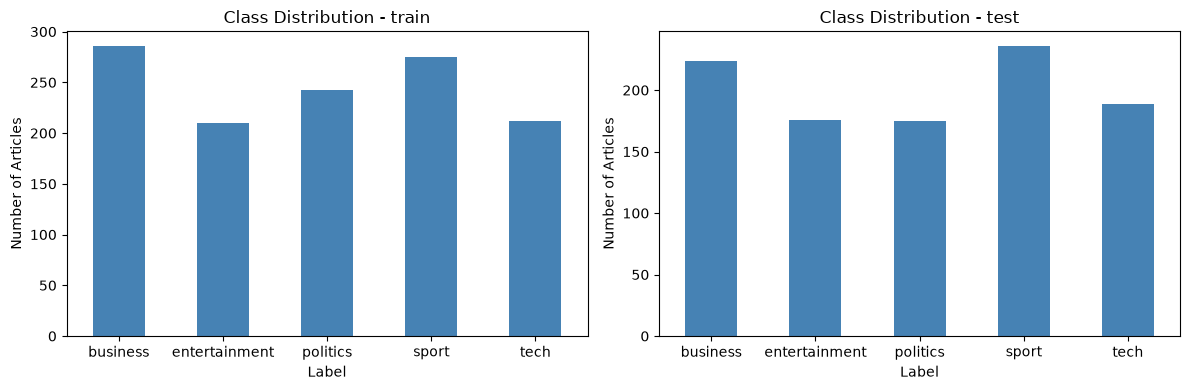

In [10]:
dfs = add_text_stats(dfs)
print("Chất lượng dữ liệu:")
display(check_quality(dfs))
print("Phân bố nhãn:")
display(label_distribution(dfs))
plot_label_distribution(dfs)

Thống kê độ dài văn bản:


train                                 test             \
      char_count word_count sentence_count char_count word_count   
count    1225.00    1225.00        1225.00    1000.00    1000.00   
mean     2288.95     395.02          20.02    2231.07     384.51   
std      1508.46     268.24          15.00    1163.07     204.67   
min       501.00      90.00           4.00     719.00     116.00   
25%      1444.00     249.00          13.00    1446.75     250.75   
50%      1976.00     340.00          18.00    1951.50     334.00   
75%      2810.00     485.00          24.00    2778.25     470.00   
max     25483.00    4492.00         250.00   16158.00    3007.00   

                      
      sentence_count  
count        1000.00  
mean           19.39  
std            10.27  
min             6.00  
25%            13.00  
50%            17.00  
75%            24.00  
max           169.00

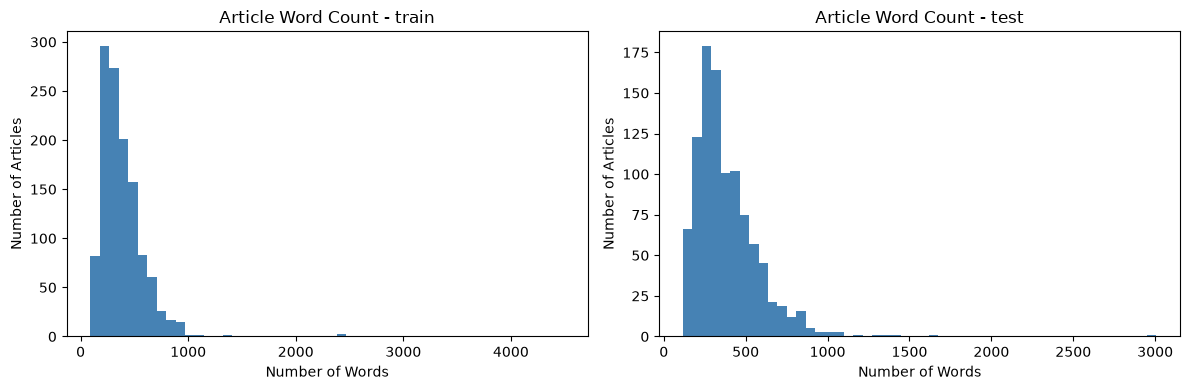

In [11]:
print("Thống kê độ dài văn bản:")
display(describe_text_stats(dfs))
plot_word_count_hist(dfs)

Độ dài (số từ) theo nhãn:


,split,count,mean,median,min,max,std
label_text,,,,,,,
business,train,286,341.30,308.0,142,912,145.11
entertainment,train,210,337.14,260.0,144,3570,328.78
politics,train,242,470.24,439.0,90,4492,377.86
sport,train,275,334.93,297.0,117,1387,170.89
tech,train,212,516.90,469.0,165,1549,218.01
business,test,224,325.10,297.5,145,902,128.12
entertainment,test,176,338.31,280.5,147,1300,171.88
politics,test,175,448.69,459.0,157,1212,153.93
sport,test,236,337.94,292.0,116,1671,213.28


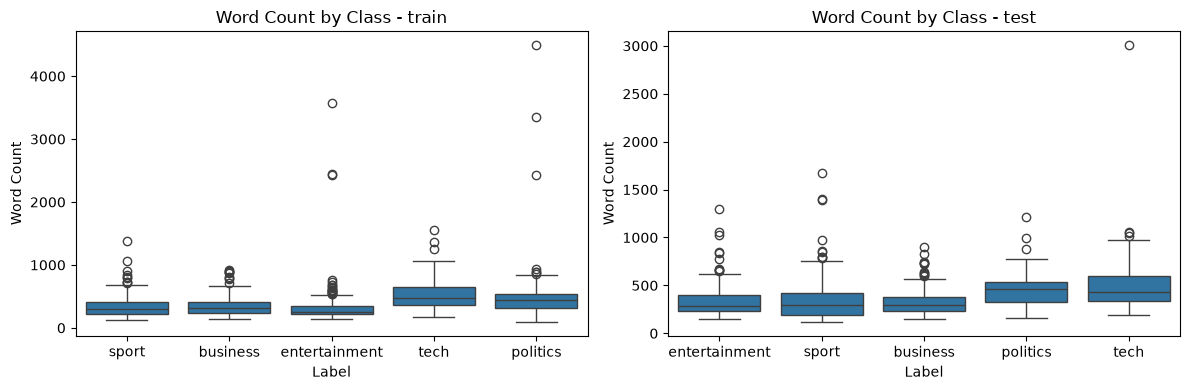

In [12]:
print("Độ dài (số từ) theo nhãn:")
display(word_count_by_class(dfs))
plot_word_count_boxplot(dfs)

In [13]:
show_examples(dfs, n=1, max_chars=300)
print("\nCác bài rất ngắn (<20 từ) ở train:")
display(short_articles(dfs["train"]))
print("Các bài dài nhất ở train:")
display(longest_articles(dfs["train"], n=5))


--- Label: business ---
[1] china aviation seeks rescue deal scandal-hit jet fuel supplier china aviation oil has offered to repay its creditors $220m (£117m) of the $550m it lost on trading in oil futures.  the firm said it hoped to pay $100m now and another $120m over eight years. with assets of $200m and liabilities totalli ...

--- Label: entertainment ---
[1] rock band u2 break ticket record u2 have smashed irish box office records with ticket sales for their dublin concerts  after more than 150 000 were sold within 50 minutes.  tickets for the two concerts at the city s croke park stadium were released at 8am on friday morning.  nothing like it has ever ...

--- Label: politics ---
[1] iraq advice claim sparks new row the tories say ministers must respond in parliament to claims that the legal advice used to justify the iraq war was drawn up at number 10.  downing street has denied the claims  made in a new book about the attorney general lord goldsmith s advice. lord goldsmith 

,text,label,word_count


Các bài dài nhất ở train:


,text,label,word_count
756,terror powers expose tyranny the lord chance...,4,4492
196,scissor sisters triumph at brits us band sciss...,3,3570
538,minimum wage increased to £5.05 the minimum wa...,4,3345
806,roundabout continues nostalgia trip the new bi...,3,2448
6,brits debate over urban music joss stone a ...,3,2430


In [14]:
print("Từ xuất hiện nhiều nhất theo nhãn (train, đã bỏ stop words):")
display(top_words_by_class(prepare_data(dfs)[0], n=8))
print("Bảng tổng hợp:")
display(summary_table(dfs))

Từ xuất hiện nhiều nhất theo nhãn (train, đã bỏ stop words):


,business,entertainment,politics,sport,tech
0,said,said,said,said,said
1,bn,film,mr,year,people
2,year,best,labour,game,technology
3,mr,music,government,world,mr
4,market,year,people,time,mobile
5,company,new,party,england,users
6,new,won,election,win,music
7,economy,years,blair,players,new


Bảng tổng hợp:


,split,rows,columns,missing_values,duplicates,mean_words,median_words,min_words,max_words,num_classes
0,train,1225,6,0,31,395.0,340.0,90,4492,5
1,test,1000,6,0,26,384.5,334.0,116,3007,5


## 3. Tiền xử lý
- Chuẩn hóa văn bản (lowercase, bỏ URL/HTML, chỉ giữ chữ cái) → cột `clean_text` (dùng cho TF-IDF).
- Loại bài trùng lặp trong từng split và loại khỏi test những bài đã có trong train (tránh rò rỉ dữ liệu).
- BERT dùng văn bản gốc (`text`) vì mô hình đã có tokenizer riêng.

In [15]:
train_df, test_df, info = prepare_data(dfs)
print(info)

label_names = get_label_names(train_df)
n_classes = len(label_names)
y_train = train_df["label"].values
y_test = test_df["label"].values
print("Nhãn:", label_names)
print("Mẫu train/test:", len(train_df), len(test_df))
print("\nVí dụ clean_text:", train_df["clean_text"].iloc[0][:200], "...")

np.save(FEATURES_DIR / "labels_train.npy", y_train)
np.save(FEATURES_DIR / "labels_test.npy", y_test)

{'train_raw': 1225, 'test_raw': 1000, 'train_after_dedup': 1193, 'test_after_dedup': 974, 'train_test_overlap': 45, 'train_final': 1193, 'test_final': 929}
Nhãn: ['tech', 'business', 'sport', 'entertainment', 'politics']
Mẫu train/test: 1193 929

Ví dụ clean_text: wales want rugby league training wales could follow england s lead by training with a rugby league club england have already had a three day session with leeds rhinos and wales are thought to be inter ...


## 4. Trích xuất đặc trưng

### 4.1. Method 1 — TF-IDF (unigram + bigram, 20.000 đặc trưng)

In [16]:
X_train_tfidf, X_test_tfidf, tfidf = build_tfidf(train_df["clean_text"], test_df["clean_text"])
print("X_train_tfidf:", X_train_tfidf.shape, "| X_test_tfidf:", X_test_tfidf.shape)

print("Đã lưu:", save_features(X_train_tfidf, FEATURES_DIR / "tfidf_train"))
print("Đã lưu:", save_features(X_test_tfidf, FEATURES_DIR / "tfidf_test"))

X_train_tfidf: (1193, 20000) | X_test_tfidf: (929, 20000)
Đã lưu: /home/gacute/Documents/BTL_ML/ml_assignment_project/standalone_output/features/tfidf_train.h5
Đã lưu: /home/gacute/Documents/BTL_ML/ml_assignment_project/standalone_output/features/tfidf_test.h5


### 4.2. Method 2 — BERT embeddings (`bert-base-uncased`, vector [CLS], max_length=256)
Nạp cache khi nội dung, thứ tự văn bản và cấu hình BERT khớp; nếu không thì trích xuất lại.

In [17]:
X_train_bert = bert_features_cached(train_df["text"].astype(str).tolist(), FEATURES_DIR / "bert_train.npy")
X_test_bert = bert_features_cached(test_df["text"].astype(str).tolist(), FEATURES_DIR / "bert_test.npy")
print("X_train_bert:", X_train_bert.shape, "| X_test_bert:", X_test_bert.shape)

Loading weights: 100%|██████████| 199/199 [00:00<00:00, 4603.15it/s]
[transformers] BertModel LOAD REPORT from: bert-base-uncased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
Loading weights: 100%|██████████| 199/199 [00:00<00:00, 11030.93it/s]
[transformers] BertModel LOAD REPORT from: bert-base-uncased
Key                                        | Status     |  |

X_train_bert: (1193, 768) | X_test_bert: (929, 768)


## 5. Thực nghiệm
Mỗi tổ hợp (đặc trưng × mô hình) được huấn luyện trên tập train và đánh giá trên tập test.

In [18]:
results = {}      # {tên: {"features": ..., "y_pred": ...}}
histories = {}    # lịch sử huấn luyện của MLP

def record(name, feat, y_pred):
    results[name] = {"features": feat, "y_pred": np.asarray(y_pred)}
    print_report(y_test, y_pred, name, label_names)

### 5.1. Naive Bayes (Gaussian, tự cài đặt)

In [19]:
nb_tfidf = NaiveBayes().fit(X_train_tfidf, y_train)
record("Naive Bayes (TF-IDF)", "TF-IDF", nb_tfidf.predict(X_test_tfidf))

========== Naive Bayes (TF-IDF) ==========
               precision    recall  f1-score   support

         tech       0.88      0.96      0.92       150
     business       0.97      0.91      0.94       221
        sport       1.00      0.99      0.99       228
entertainment       0.99      0.85      0.91       163
     politics       0.85      0.98      0.91       167

     accuracy                           0.94       929
    macro avg       0.94      0.94      0.93       929
 weighted avg       0.94      0.94      0.94       929



In [20]:
nb_bert = NaiveBayes().fit(X_train_bert, y_train)
record("Naive Bayes (BERT)", "BERT", nb_bert.predict(X_test_bert))

# Kiểm tra tính đúng đắn: so với GaussianNB của scikit-learn trên cùng đặc trưng
sk_pred = GaussianNB().fit(X_train_bert, y_train).predict(X_test_bert)
print("Tỉ lệ dự đoán trùng với sklearn GaussianNB:", (sk_pred == results["Naive Bayes (BERT)"]["y_pred"]).mean())

========== Naive Bayes (BERT) ==========
               precision    recall  f1-score   support

         tech       0.88      0.85      0.86       150
     business       0.92      0.88      0.90       221
        sport       0.99      0.96      0.98       228
entertainment       0.85      0.96      0.90       163
     politics       0.92      0.92      0.92       167

     accuracy                           0.92       929
    macro avg       0.91      0.91      0.91       929
 weighted avg       0.92      0.92      0.92       929

Tỉ lệ dự đoán trùng với sklearn GaussianNB: 1.0


### 5.2. Decision Tree

In [21]:
dt_tfidf = DecisionTreeClassifier(random_state=SEED).fit(X_train_tfidf, y_train)
record("Decision Tree (TF-IDF)", "TF-IDF", dt_tfidf.predict(X_test_tfidf))

========== Decision Tree (TF-IDF) ==========
               precision    recall  f1-score   support

         tech       0.77      0.59      0.66       150
     business       0.71      0.73      0.72       221
        sport       0.86      0.89      0.88       228
entertainment       0.75      0.80      0.77       163
     politics       0.75      0.79      0.77       167

     accuracy                           0.77       929
    macro avg       0.77      0.76      0.76       929
 weighted avg       0.77      0.77      0.77       929



In [22]:
dt_bert = DecisionTreeClassifier(random_state=SEED).fit(X_train_bert, y_train)
record("Decision Tree (BERT)", "BERT", dt_bert.predict(X_test_bert))

========== Decision Tree (BERT) ==========
               precision    recall  f1-score   support

         tech       0.67      0.67      0.67       150
     business       0.72      0.73      0.73       221
        sport       0.84      0.79      0.81       228
entertainment       0.72      0.72      0.72       163
     politics       0.69      0.73      0.71       167

     accuracy                           0.73       929
    macro avg       0.73      0.73      0.73       929
 weighted avg       0.73      0.73      0.73       929



### 5.3. MLP (6 lớp ẩn: 1024-512-256-128-64-32, Dropout 0.5, BatchNorm, Adam lr=1e-3)

In [23]:
mlp_tfidf = MLP(X_train_tfidf.shape[1], n_classes).fit(X_train_tfidf, y_train, epochs=60)
record("MLP (TF-IDF)", "TF-IDF", mlp_tfidf.predict(X_test_tfidf))
histories["MLP (TF-IDF)"] = {"loss": mlp_tfidf.history_loss, "accuracy": mlp_tfidf.history_accuracy}

Epoch   1/60 | loss 1.7058 | acc 0.2188
Epoch  10/60 | loss 0.8252 | acc 0.7502
Epoch  20/60 | loss 0.2570 | acc 0.9455
Epoch  30/60 | loss 0.1288 | acc 0.9698
Epoch  40/60 | loss 0.1078 | acc 0.9707
Epoch  50/60 | loss 0.0798 | acc 0.9883
Epoch  60/60 | loss 0.0816 | acc 0.9799
========== MLP (TF-IDF) ==========
               precision    recall  f1-score   support

         tech       0.91      0.97      0.94       150
     business       0.96      0.95      0.95       221
        sport       0.99      1.00      0.99       228
entertainment       0.99      0.92      0.95       163
     politics       0.95      0.97      0.96       167

     accuracy                           0.96       929
    macro avg       0.96      0.96      0.96       929
 weighted avg       0.96      0.96      0.96       929



In [24]:
mlp_bert = MLP(X_train_bert.shape[1], n_classes).fit(X_train_bert, y_train, epochs=60)
record("MLP (BERT)", "BERT", mlp_bert.predict(X_test_bert))
histories["MLP (BERT)"] = {"loss": mlp_bert.history_loss, "accuracy": mlp_bert.history_accuracy}

Epoch   1/60 | loss 1.7018 | acc 0.2129
Epoch  10/60 | loss 0.7386 | acc 0.7963
Epoch  20/60 | loss 0.3264 | acc 0.9271
Epoch  30/60 | loss 0.2283 | acc 0.9480
Epoch  40/60 | loss 0.2203 | acc 0.9447
Epoch  50/60 | loss 0.1855 | acc 0.9573
Epoch  60/60 | loss 0.2247 | acc 0.9497
========== MLP (BERT) ==========
               precision    recall  f1-score   support

         tech       0.92      0.95      0.94       150
     business       0.93      0.92      0.93       221
        sport       1.00      0.99      0.99       228
entertainment       0.95      0.98      0.96       163
     politics       0.96      0.93      0.94       167

     accuracy                           0.95       929
    macro avg       0.95      0.95      0.95       929
 weighted avg       0.95      0.95      0.95       929



## 6. So sánh kết quả

,Model,Features,Accuracy (%),Macro Precision (%),Macro Recall (%),Macro F1 (%),Weighted F1 (%)
0,Naive Bayes (TF-IDF),TF-IDF,93.86,93.69,93.70,93.44,93.89
1,Naive Bayes (BERT),BERT,91.71,91.21,91.48,91.27,91.73
2,Decision Tree (TF-IDF),TF-IDF,77.07,76.76,76.05,76.13,76.84
3,Decision Tree (BERT),BERT,73.30,72.69,72.78,72.71,73.37
4,MLP (TF-IDF),TF-IDF,96.12,95.92,95.97,95.90,96.13
5,MLP (BERT),BERT,95.37,95.17,95.34,95.24,95.37


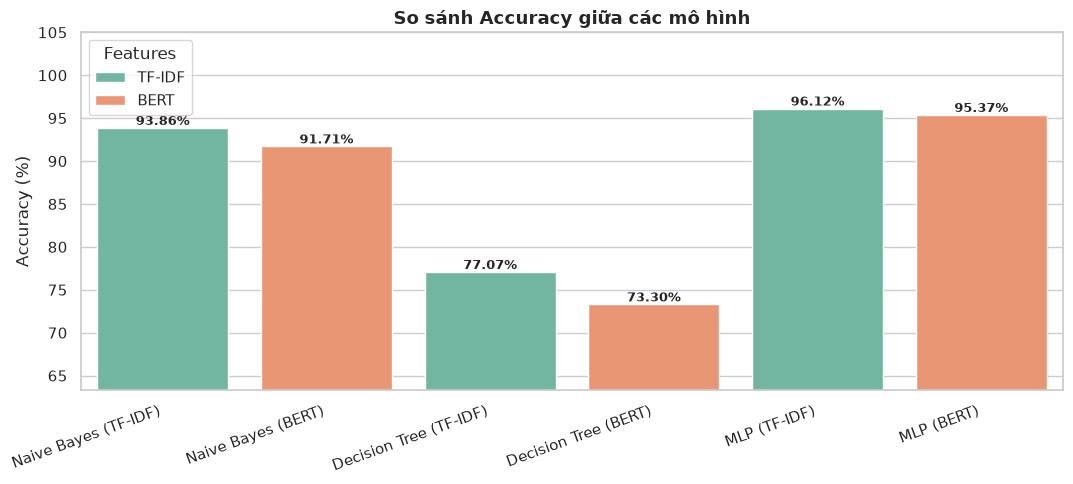

In [25]:
df_compare = compare_models(y_test, results)
display(df_compare)
df_compare.to_csv(REPORTS_DIR / "results_table.csv", index=False)

plot_accuracy_comparison(df_compare, save_path=REPORTS_DIR / "accuracy_comparison.png")

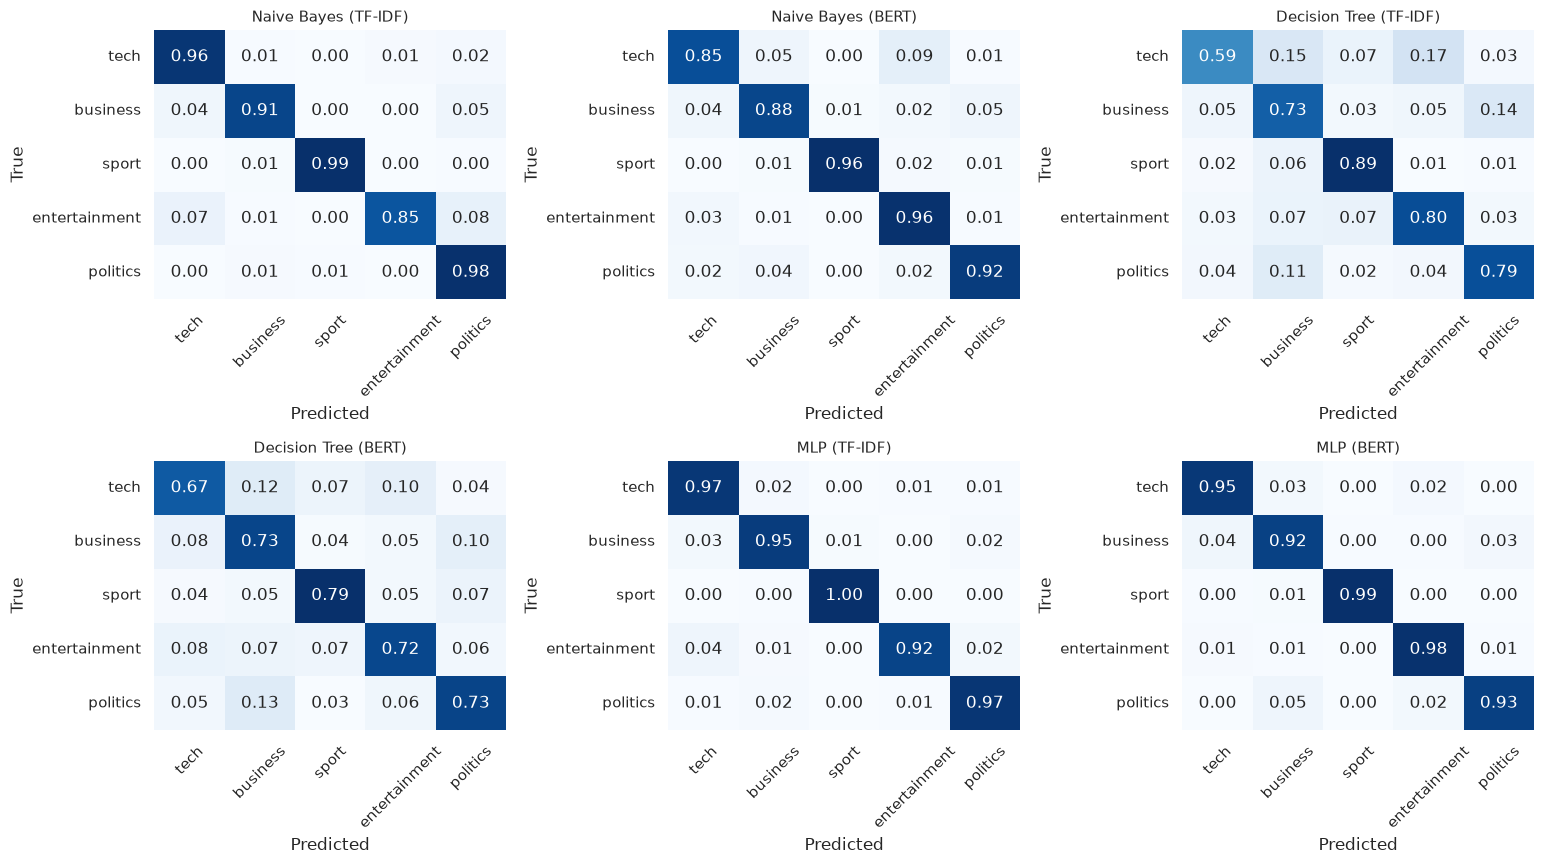

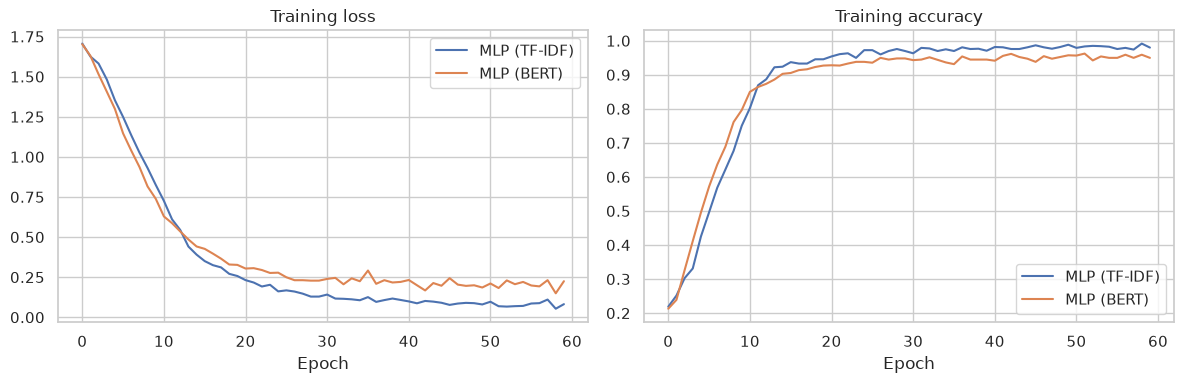

In [26]:
plot_confusion_matrices(
    y_test, {k: v["y_pred"] for k, v in results.items()}, label_names,
    save_path=REPORTS_DIR / "confusion_matrices.png",
)
plot_training_curves(histories, save_path=REPORTS_DIR / "mlp_training_curves.png")

## 7. Phân tích & nhận xét
*(Điền nhận xét của nhóm: so sánh TF-IDF vs BERT, so sánh 3 mô hình, các lớp hay bị nhầm lẫn,
ưu/nhược điểm từng phương pháp, hạn chế và hướng cải thiện. Chi tiết đưa vào báo cáo PDF.)*

## 8. Đóng gói đặc trưng đã trích xuất
Các file `.npy`/`.h5` nằm trong thư mục `features/`; cell dưới nén chúng thành một file `.zip` để tải xuống từ panel Files của Colab.

In [27]:
import shutil
for f in sorted(FEATURES_DIR.iterdir()):
    print(f.name, f"{f.stat().st_size / 1e6:.1f} MB")
archive_path = shutil.make_archive(str(OUTPUT_DIR / "features_export"), "zip", FEATURES_DIR)
print("Đã tạo:", archive_path)

bert_test.json 0.0 MB
bert_test.npy 2.9 MB
bert_train.json 0.0 MB
bert_train.npy 3.7 MB
labels_test.npy 0.0 MB
labels_train.npy 0.0 MB
tfidf_test.h5 1.3 MB
tfidf_train.h5 1.9 MB
Đã tạo: /home/gacute/Documents/BTL_ML/ml_assignment_project/standalone_output/features_export.zip
